In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set seaborn style for better looking charts
sns.set_theme(style="darkgrid")

def load_replay(filepath):
    print(f"Loading {filepath}...")
    try:
        # Added utf-8 encoding for safety
        with open(filepath, 'r', encoding='utf-8') as f:
            html_content = f.read()
        
        # Chop off everything before the JSON payload
        raw_tail = html_content.split('window.kaggle = ', 1)[1]
        
        # Chop off everything after the JSON payload
        json_string_candidate = raw_tail.split('window.kaggle.renderer', 1)[0]
        
        # Strip trailing newlines and the JavaScript semicolon so it's pure JSON
        clean_json_string = json_string_candidate.strip().rstrip(';')
        
        # Parse it!
        data = json.loads(clean_json_string)
        return data['environment']['steps']
        
    except FileNotFoundError:
        print(f"Error: Could not find the file at {filepath}. Check your relative path!")
        return None
    except Exception as e:
        # Now it will actually tell us what broke if it fails
        print(f"Failed to parse JSON from HTML: {e}")
        return None

# Make sure this path exactly matches where your script saved the file!
steps = load_replay("../replays/replay_match_1_2-player_seed539340.html")

if steps is not None:
    print(f"Successfully loaded {len(steps)} turns.")

Loading ../replays/replay_match_1_2-player_seed539340.html...
Successfully loaded 186 turns.


In [8]:
economy_data = []
fleet_launches = []
seen_fleets = set()

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    p0_planet_ships = 0
    p1_planet_ships = 0
    p0_fleet_ships = 0
    p1_fleet_ships = 0
    
    # Tally Planet Economy
    for p in planets:
        owner = p[1]
        ships = p[5]
        if owner == 0: p0_planet_ships += ships
        elif owner == 1: p1_planet_ships += ships
            
    # Tally Fleet Economy & Detect New Launches
    for f in fleets:
        f_id = f[0]
        owner = f[1]
        ships = f[6]
        
        if owner == 0: p0_fleet_ships += ships
        elif owner == 1: p1_fleet_ships += ships
            
        # Detect new fleet launches (Trickle Bleed tracker)
        if f_id not in seen_fleets:
            seen_fleets.add(f_id)
            fleet_launches.append({
                'turn': turn_idx,
                'owner': owner,
                'ships': ships
            })
            
    economy_data.append({
        'turn': turn_idx,
        'P0_Planets': p0_planet_ships,
        'P1_Planets': p1_planet_ships,
        'P0_Fleets': p0_fleet_ships,
        'P1_Fleets': p1_fleet_ships,
        'P0_Total': p0_planet_ships + p0_fleet_ships,
        'P1_Total': p1_planet_ships + p1_fleet_ships
    })

df_eco = pd.DataFrame(economy_data)
df_launches = pd.DataFrame(fleet_launches)

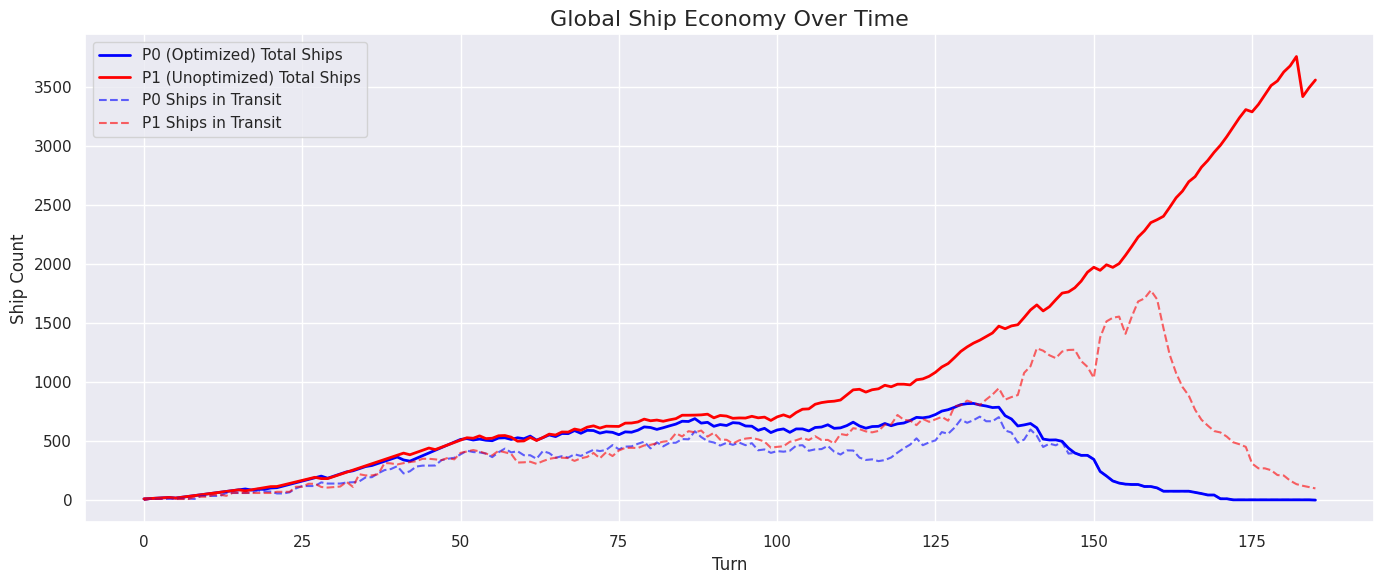

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(df_eco['turn'], df_eco['P0_Total'], label='P0 (Optimized) Total Ships', color='blue', linewidth=2)
plt.plot(df_eco['turn'], df_eco['P1_Total'], label='P1 (Unoptimized) Total Ships', color='red', linewidth=2)

plt.plot(df_eco['turn'], df_eco['P0_Fleets'], label='P0 Ships in Transit', color='blue', linestyle='--', alpha=0.6)
plt.plot(df_eco['turn'], df_eco['P1_Fleets'], label='P1 Ships in Transit', color='red', linestyle='--', alpha=0.6)

plt.title('Global Ship Economy Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ship Count', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

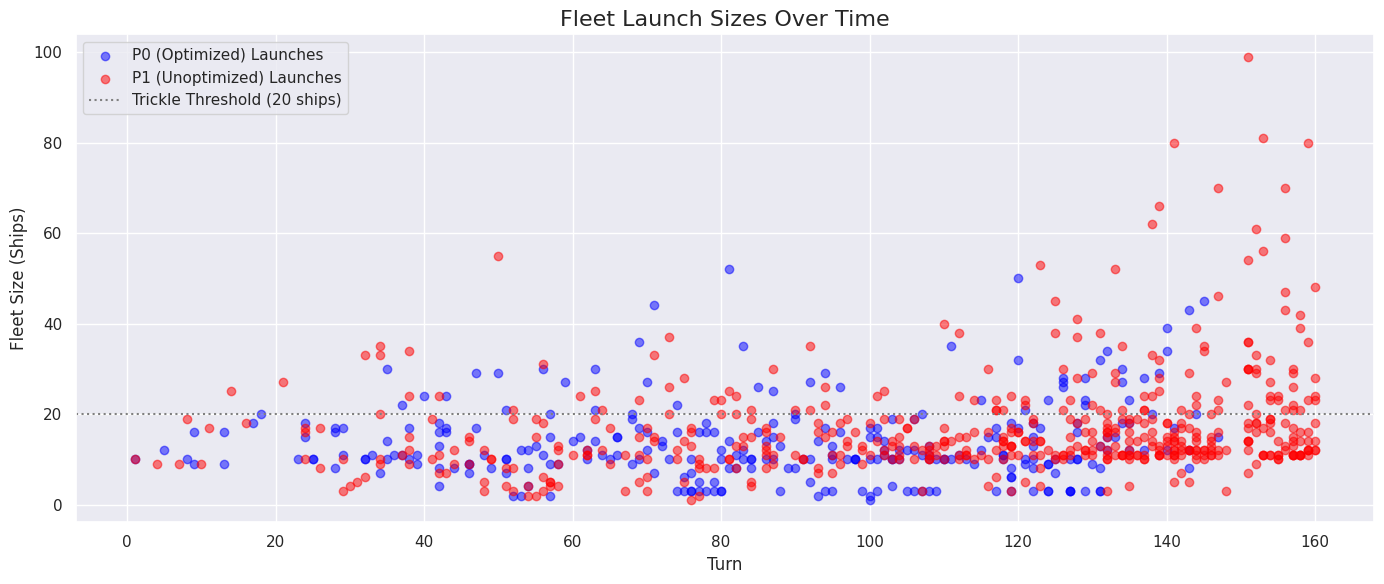

In [10]:
plt.figure(figsize=(14, 6))

# Separate launches by player
p0_launches = df_launches[df_launches['owner'] == 0]
p1_launches = df_launches[df_launches['owner'] == 1]

plt.scatter(p0_launches['turn'], p0_launches['ships'], color='blue', alpha=0.5, label='P0 (Optimized) Launches')
plt.scatter(p1_launches['turn'], p1_launches['ships'], color='red', alpha=0.5, label='P1 (Unoptimized) Launches')

# Add a threshold line to highlight "trickle" fleets
plt.axhline(y=20, color='gray', linestyle=':', label='Trickle Threshold (20 ships)')

plt.title('Fleet Launch Sizes Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Fleet Size (Ships)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

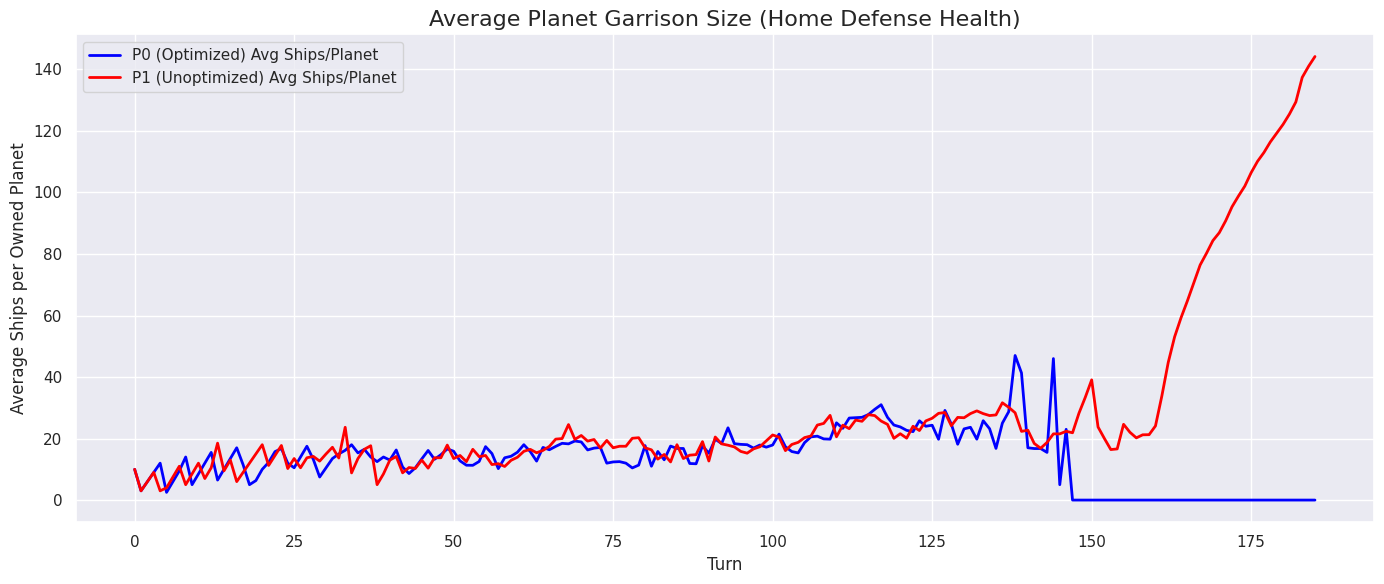

In [12]:
# Cell: Planet Garrison Health Over Time
garrison_data = []

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    
    p0_planets = [p[5] for p in planets if p[1] == 0]
    p1_planets = [p[5] for p in planets if p[1] == 1]
    
    garrison_data.append({
        'turn': turn_idx,
        'P0_Avg_Garrison': sum(p0_planets) / len(p0_planets) if p0_planets else 0,
        'P1_Avg_Garrison': sum(p1_planets) / len(p1_planets) if p1_planets else 0,
    })

df_garrison = pd.DataFrame(garrison_data)

plt.figure(figsize=(14, 6))
plt.plot(df_garrison['turn'], df_garrison['P0_Avg_Garrison'], label='P0 (Optimized) Avg Ships/Planet', color='blue', linewidth=2)
plt.plot(df_garrison['turn'], df_garrison['P1_Avg_Garrison'], label='P1 (Unoptimized) Avg Ships/Planet', color='red', linewidth=2)
plt.title('Average Planet Garrison Size (Home Defense Health)', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Average Ships per Owned Planet', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

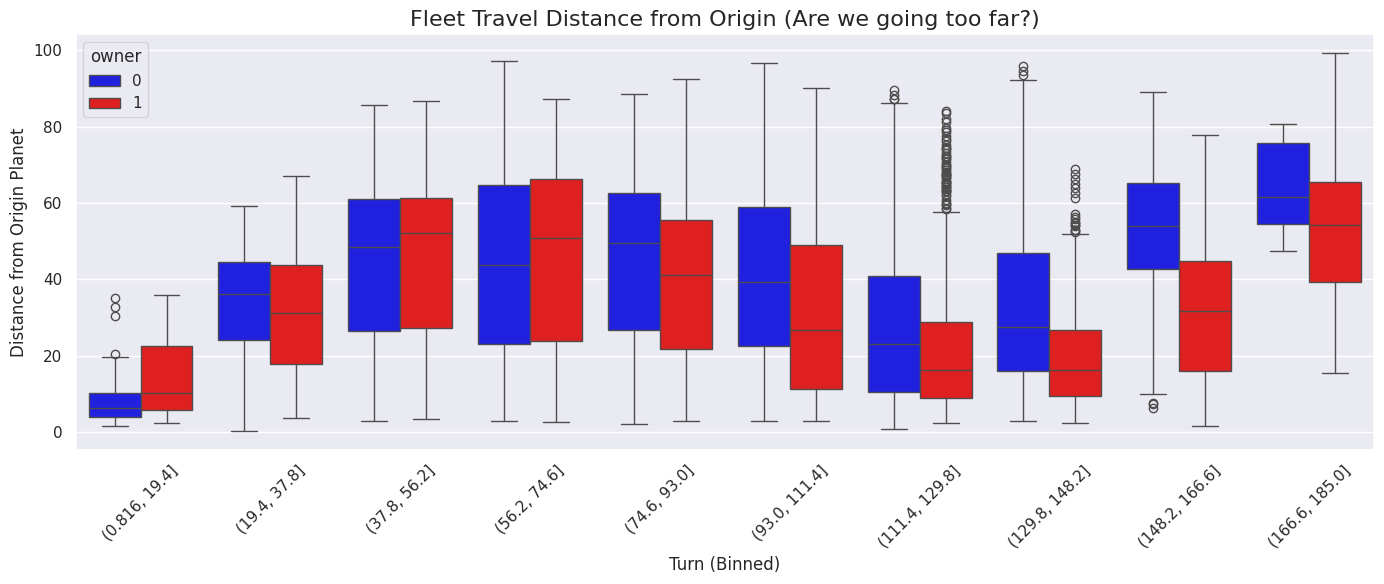

In [15]:
# Cell: Fleet Travel Distance Approximation
travel_data = []

# Get static initial planet locations for origin mapping
initial_planets = steps[0][0]['observation']['planets']
planet_coords = {p[0]: (p[2], p[3]) for p in initial_planets}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    fleets = obs.get('fleets', [])
    
    for f in fleets:
        owner = f[1]
        fx, fy = f[2], f[3]
        origin_id = f[5]
        
        # Calculate distance from origin
        ox, oy = planet_coords.get(origin_id, (50, 50))
        dist_from_home = math.hypot(fx - ox, fy - oy)
        
        travel_data.append({
            'turn': turn_idx,
            'owner': owner,
            'dist_from_home': dist_from_home,
            'ships': f[6]
        })

df_travel = pd.DataFrame(travel_data)

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_travel, 
    x=pd.cut(df_travel['turn'], bins=10), 
    y='dist_from_home', 
    hue='owner',
    palette={0: "blue", 1: "red"}
)
plt.title('Fleet Travel Distance from Origin (Are we going too far?)', fontsize=16)
plt.xlabel('Turn (Binned)', fontsize=12)
plt.ylabel('Distance from Origin Planet', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()